# Lesson 8.1: Correlation: Do Two Numbers Move Together?

Measure how strongly study hours and exam scores move together for the lesson's eight students, with Pearson's r, Spearman's rho and a scatter plot.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

A teacher wonders whether studying more goes with higher exam scores. Eight students reported the hours they studied in the week before the exam (1 to 8 hours) and then their exam score. How strongly do hours and score move together, and with only eight students, could the pattern be luck?

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: Enter the data and look at it

Eight students: hours studied and exam score. Always draw the scatter plot before trusting a correlation number, because the plot shows the pattern, outliers and curves that one number hides.

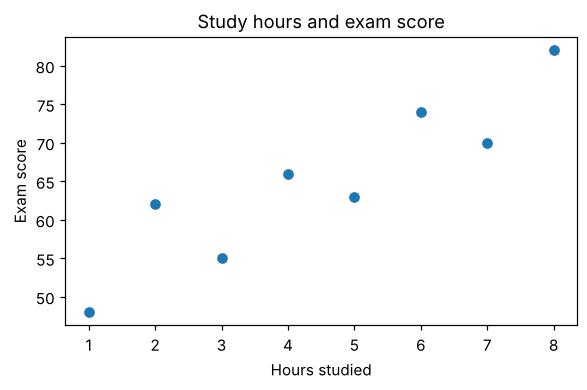

In [1]:
import numpy as np  # Load NumPy, the library for arrays of numbers, under the short name np.
import matplotlib.pyplot as plt  # Load matplotlib's plotting tools as plt, so we can draw the scatter plot.
from scipy import stats  # Load SciPy's statistics tools, which contain the correlation functions.

hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Store the hours studied by the eight students as an array, one number per student.
score = np.array([48, 62, 55, 66, 63, 74, 70, 82])  # Store their exam scores in the same order, so the first score belongs to the first hours value.

plt.figure(figsize=(6, 3.4))  # Start a new figure. figsize=(6, 3.4) sets its width and height in inches so it fits the page.
plt.scatter(hours, score, color='#1f77b4')  # Draw one dot per student, hours across and score up. Always plot first: one number can hide curves and outliers.
plt.xlabel('Hours studied')  # Label the horizontal axis so a reader knows what it shows.
plt.ylabel('Exam score')  # Label the vertical axis too.
plt.title('Study hours and exam score')  # Add a title that says in words what the plot is about.
plt.show()  # Show the figure.

**What this means.** The dots climb from lower left to upper right in a fairly straight band. Students who studied more tended to score more. The 3-hour student (55) scored below the 2-hour student (62), so it is not perfect. There is no wild outlier, so a straight-line measure like Pearson's r is a fair choice.

## Step 2: Pearson's r

pearsonr measures the strength of a straight-line link from -1 to +1. It also returns a p-value for the test that the true correlation is 0, which uses the t distribution with n - 2 degrees of freedom.

In [2]:
res = stats.pearsonr(hours, score)  # Pearson's correlation: pearsonr returns r (strength of the straight-line link) and a p-value for 'is the true correlation 0?'.

print(f'r       = {res.statistic:.3f}')  # Print r, from -1 (perfect downhill) through 0 (no straight-line link) to +1 (perfect uphill).
print(f'r squared = {res.statistic ** 2:.3f}')  # Squaring r gives the share of the variation in scores that moves together with hours.
print(f'p-value = {res.pvalue:.4f}')  # The p-value says how rare an r this far from 0 would be if the true correlation were 0.
print('df      =', len(hours) - 2)  # Degrees of freedom for this test are n - 2. We print them because the t-test behind the p-value uses them.

r       = 0.907
r squared = 0.822
p-value = 0.0019
df      = 6


**What this means.** r = 0.907 is a strong positive link. r squared = 0.822, so about 82% of the ups and downs in score go along with hours. The p-value is 0.0019 (6 df): if hours and scores were truly unrelated, an r this large from 8 students would be very unusual. So luck is an unlikely explanation.

## Step 3: Spearman's rho (the rank version)

Spearman replaces each value by its rank and then correlates the ranks. It catches any steadily rising or falling pattern, curved or not, and is less bothered by outliers.

In [3]:
sp = stats.spearmanr(hours, score)  # Spearman's rho: spearmanr replaces every value by its rank and correlates the ranks, so it catches any steady rise or fall.

print(f'rho     = {sp.statistic:.3f}')  # Print rho. It is also between -1 and +1 and is less bothered by outliers.
print(f'p-value = {sp.pvalue:.4f}')  # Print its p-value, the chance of a rho this far from 0 if there were no link at all.

rho     = 0.929
p-value = 0.0009


**What this means.** rho = 0.929 is even higher than r, because the ranks are almost perfectly in step. The p-value of 0.0009 is an approximation (R reports an exact 0.0022). Since the rank version agrees with Pearson's, the result does not depend on one odd student.

## Step 4: Correlation is not causation

A strong r tells us hours and score rise together. It cannot tell us that studying causes the higher scores: keen, well-prepared students may both study more and score higher. Only a well-designed experiment can settle cause.

In [4]:
print(f'r = {res.statistic:.2f}: the two variables rise together.')  # Print r rounded to 2 decimals and say in words what it shows: the two variables rise together.
print('That does NOT prove that extra hours caused extra points.')  # Remind ourselves that a strong correlation does not prove that studying caused the higher scores.
print('Something else (motivation, prior skill) could drive both.')  # Name a possible hidden driver. Motivation or prior skill could lift both hours and scores.

r = 0.91: the two variables rise together.
That does NOT prove that extra hours caused extra points.
Something else (motivation, prior skill) could drive both.


**What this means.** r = 0.91 tells us the pattern is strong, not why it happens. Perhaps studying raises scores, or perhaps keen, well-prepared students both study more and score higher. A correlation alone cannot separate these. Only a well-designed experiment can.

## So, what is the answer?

Yes, in these eight students more study hours went with higher scores, and the link is strong: r = 0.91 (about 82% of the variation moves together), with p = 0.0019, so it is unlikely to be luck. Caution: this does not show that studying causes higher scores, and eight students from one class is a small sample.

## Now you try

A cafe owner records the day's high temperature (degrees Celsius) and the number of ice-cream cones sold on ten days. How strongly are temperature and sales linked, and does that prove heat makes people buy ice cream?

**Data:** temp = [14, 16, 18, 20, 22, 24, 26, 28, 30, 32]
sales = [210, 250, 235, 300, 320, 310, 380, 400, 390, 450]

1. Compute Pearson's r, its p-value and r squared.
2. Compute Spearman's rho and compare it with r.
3. In one sentence, say what you can and cannot conclude.

*Hint:* Use stats.pearsonr and stats.spearmanr on the two lists. Square r to get the share of variation that moves together.

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np
from scipy import stats

temp = np.array([14, 16, 18, 20, 22, 24, 26, 28, 30, 32])
sales = np.array([210, 250, 235, 300, 320, 310, 380, 400, 390, 450])
r = stats.pearsonr(temp, sales)
rho = stats.spearmanr(temp, sales)
print(f'r = {r.statistic:.3f}, p = {r.pvalue:.1e}, r squared = {r.statistic ** 2:.3f}')
print(f'rho = {rho.statistic:.3f}, p = {rho.pvalue:.1e}')

r = 0.973, p = 2.2e-06, r squared = 0.947
rho = 0.964, p = 7.3e-06


**Answer.** r = 0.973 with p = 2.2e-06 (0.0000022) and r squared = 0.947, so about 95% of the variation in sales moves together with temperature. Spearman's rho = 0.964 (p = 7.3e-06) agrees. Hot days clearly go with more sales. But this is correlation: it does not prove heat alone causes the sales, since hot days also bring more people outdoors.

## The same question in R, SPSS and Stata

**R**

```r
hours <- c(1, 2, 3, 4, 5, 6, 7, 8)  # Store the hours studied by the eight students as a vector. c() means combine.
score <- c(48, 62, 55, 66, 63, 74, 70, 82)  # Store their scores in the same order.
plot(hours, score)  # Draw the scatter plot of score against hours. Always look at the picture before trusting a number.
cor.test(hours, score)  # cor.test gives Pearson's r by default, with a t-test, a p-value and a 95% confidence interval.
cor.test(hours, score, method = "spearman")  # method = "spearman" ranks the values first and gives Spearman's rho and its p-value.
```

How to read it: In the first test find cor 0.9067, t = 5.267, df = 6, p-value = 0.001889 and the 95 percent interval 0.5597 to 0.9832: a strong link unlikely to be luck. In the second, rho 0.9286 and p-value = 0.002232 (an exact p, so larger than Python's approximate 0.0009).

**SPSS** (Analyze > Correlate > Bivariate (tick Pearson and Spearman); Graphs > Chart Builder > Scatter/Dot)

```
DATA LIST FREE / hours score.
BEGIN DATA
1 48  2 62  3 55  4 66  5 63  6 74  7 70  8 82
END DATA.
GRAPH /SCATTERPLOT(BIVAR)=hours WITH score.
CORRELATIONS /VARIABLES=hours score.
NONPAR CORR /VARIABLES=hours score /PRINT=SPEARMAN TWOTAIL.
```

How to read it: In the Correlations table read Pearson Correlation = .907 and Sig. (2-tailed) = .002: a strong link, unlikely by chance. In the Nonparametric Correlations table read Correlation Coefficient = .929 (rho) and Sig. (2-tailed) about .001.

**Stata**

```
clear
set obs 8
generate hours = _n
generate score = real(word("48 62 55 66 63 74 70 82", _n))
scatter score hours
pwcorr hours score, sig
spearman hours score
```

How to read it: pwcorr shows 0.9067 with 0.0019 under it: r and its p-value, a strong link unlikely to be luck. spearman shows Number of obs = 8, Spearman's rho = 0.9286 and Prob > |t| = 0.0009 (an approximation).